# Deep Q-Network: Balancing CartPole

**Family:** Reinforcement learning | **Level:** Advanced | **Dataset:** `CartPole-v1` | **Runs on:** CPU, about 3 minute(s)

Approximate Q values with a neural network, experience replay and a target network.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- Why a table cannot hold continuous states
- How replay and target networks stabilise training
- Epsilon schedules
- How to read noisy RL learning curves

**Prerequisites:**

- Probability basics
- Markov decision processes

**Skills you will have afterwards:**

- Run several seeds
- Report learning curves with spread
- Compare with a baseline policy

## 2. Real-World Problem

**Context.** Balancing an unstable system is a standard control benchmark.

**The problem.** Learn to keep the pole up by pushing the cart, from state observations only.

**Why it matters.** The same value approximation ideas drive agents for games and robots.

**Why machine learning.** The state is continuous, so a lookup table is impossible.

**Why this algorithm.** DQN is the reference deep value method for discrete actions.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### Human-level control through deep reinforcement learning

- **Type:** foundational paper
- **Authors:** Mnih, V. et al.
- **Year and venue:** 2015, Nature 518(7540):529-533
- **DOI or URL:** https://doi.org/10.1038/nature14236
- **Verification:** Crossref 2026-11-17
- **Research objective:** Learn control from pixels with one agent.
- **Methodology:** Q-learning with a deep network, experience replay and a target network.
- **Dataset:** 49 Atari 2600 games from the Arcade Learning Environment.
- **Main findings:** Reached human level on a majority of the games.
- **Limitations:** Sample hungry, discrete actions only.

### Deep Reinforcement Learning that Matters

- **Type:** benchmark paper
- **Authors:** Henderson, P. et al.
- **Year and venue:** 2018, AAAI 2018; arXiv:1709.06560
- **DOI or URL:** https://arxiv.org/abs/1709.06560
- **Verification:** arXiv abstract page 2026-11-17
- **Research objective:** Study reproducibility in deep RL.
- **Methodology:** Compare algorithms across seeds, codebases and hyperparameters.
- **Dataset:** MuJoCo tasks.
- **Main findings:** Results change strongly with seeds and implementation, so several seeds are needed.
- **Limitations:** Limited set of tasks.

**Relationship to this notebook.** Mnih et al. train DQN on Atari images with a convolutional network and millions of frames. We train a small MLP on CartPole for 20 000 steps, so no result is comparable. Henderson et al. explain why seeds and hyperparameters matter. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**Q-network.** $Q_\theta(s,a)$ approximates the optimal action value.

**Loss on a replay minibatch.** $L(\theta) = \mathbb{E}\big[\ell\big(y - Q_\theta(s,a)\big)\big]$ with target $y = r + \gamma(1-d)\max_{a'} Q_{\theta^-}(s',a')$, where $\theta^-$ are the parameters of a target network copied every $C$ steps and $\ell$ is the Huber loss.

**Replay.** Sampling past transitions at random breaks the correlation between consecutive samples.

**Exploration.** Epsilon decays linearly from 1.0 to 0.05.

**Limits.** Sample hungry, sensitive to hyperparameters, overestimates values.

## 5. Dataset Introduction

**CartPole-v1** (Gymnasium, `classic_control`). A pole is hinged to a cart. State: cart position, cart velocity, pole angle, pole angular velocity (4 real numbers). Actions: push left or right. Reward +1 per step. An episode ends when the pole falls past about 12 degrees, the cart leaves the track, or after 500 steps. The maximum return is 500, and a mean of 475 is the usual solved threshold. There is no dataset, the environment is simulated.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
from IPython.display import display

from ml_lab.rl import tabular, deep
from ml_lab.evaluation import evaluate_policy
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "dqn"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()
print("gymnasium", gym.__version__)

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0
gymnasium 1.4.0


## 6. Exploratory Data Analysis

There is no dataset. We inspect the environment: observation and action spaces, rewards and a random policy baseline. 

In [2]:
env = gym.make("CartPole-v1")
print("observation space:", env.observation_space)
print("action space:", env.action_space, "| max episode steps:", env.spec.max_episode_steps)
rng0 = np.random.default_rng(0)
random_returns = evaluate_policy(lambda: gym.make("CartPole-v1"), lambda s: int(rng0.integers(2)), episodes=50, seed=0)
print("random policy over 50 episodes:", {k: round(v, 1) for k, v in random_returns.items()})

observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
action space: Discrete(2) | max episode steps: 500
random policy over 50 episodes: {'mean_return': 25.1, 'median_return': 20.0, 'std_return': 13.6, 'mean_length': 25.1}


## 7. Data Preprocessing

No preprocessing: the 4 state values are fed directly to a network with two hidden layers of 64 units. Training uses seeds 0, 1 and 2. Evaluation uses 20 fresh episodes per seed with environment seeds from 1000, never seen in training. Only a CPU is used, so the budgets are small and results will be below long GPU runs.

In [3]:
TOTAL_STEPS = 20000
SEEDS = [0, 1, 2]
make_env = lambda: gym.make("CartPole-v1")
GRID = np.linspace(1000, TOTAL_STEPS, 40)

## 8. Algorithm Implementation

### 8.1 Concept

A network predicts the value of both actions. The agent mostly picks the larger one, and the network is trained to match one step lookahead targets.

### 8.2 Python implementation from scratch

The agent is in `ml_lab.rl.deep.train_dqn`. Source of the training function:

In [4]:
print(inspect.getsource(deep.train_dqn))

def train_dqn(env_id="CartPole-v1", seed=0, total_steps=20000, double=False, lr=1e-3, gamma=0.99, buffer_size=20000,
              batch=64, target_every=250, eps_start=1.0, eps_end=0.05, eps_decay_steps=5000, learn_start=500, hidden=64):
    """DQN, or Double DQN when double=True. Bootstraps through time limit truncation."""
    seed_everything(seed)
    rng = np.random.default_rng(seed)
    env = gym.make(env_id)
    obs_dim, n_actions = env.observation_space.shape[0], env.action_space.n
    q, q_target = mlp(obs_dim, n_actions, hidden), None
    q_target = copy.deepcopy(q)
    opt = torch.optim.Adam(q.parameters(), lr=lr)
    buffer = ReplayBuffer(buffer_size, obs_dim)
    obs, _ = env.reset(seed=seed)
    returns, steps, q_log, total = [], [], [], 0.0
    for t in range(total_steps):
        eps = max(eps_end, eps_start - (eps_start - eps_end) * t / eps_decay_steps)
        if rng.random() < eps:
            action = int(rng.integers(n_actions))
        else:
            with torch

### 8.3 Library implementation

The algorithm is implemented in `src/ml_lab/rl` without an RL library. Gymnasium supplies only the environment.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `lr` | Adam learning rate. |
| `buffer_size` | Replay capacity. |
| `target_every` | Steps between target network copies. |
| `eps_decay_steps` | Steps over which epsilon falls. |
| `double` | Use the Double DQN target. |

## 9. Model Training

Three seeds, 20 000 environment steps each, learning starts after 500 steps.

In [5]:
runs = {}
for seed in SEEDS:
    runs[seed] = deep.train_dqn(seed=seed, total_steps=TOTAL_STEPS)
    last = runs[seed]["returns"][-10:]
    print("seed", seed, "| episodes", len(runs[seed]["returns"]), "| mean training return of last 10 episodes:", round(float(np.mean(last)), 1))

seed 0 | episodes 158 | mean training return of last 10 episodes: 402.1


seed 1 | episodes 177 | mean training return of last 10 episodes: 216.2


seed 2 | episodes 207 | mean training return of last 10 episodes: 96.4


## 10. Evaluation

Evaluation return of the greedy policy on 20 fresh episodes per seed. Floor: random policy.

In [6]:
rng_eval = np.random.default_rng(0)
random_eval = evaluate_policy(make_env, lambda s: int(rng_eval.integers(2)), episodes=20, seed=1000)
evals = {seed: evaluate_policy(make_env, runs[seed]["policy"], episodes=20, seed=1000, success_threshold=475) for seed in SEEDS}
table = pd.DataFrame(evals).T[["mean_return", "std_return", "success_rate"]]
display(table.round(1))
means = np.array([e["mean_return"] for e in evals.values()])
METRICS = {"eval_mean_return": float(means.mean()), "eval_std_across_seeds": float(means.std(ddof=1)), "eval_min_seed": float(means.min()), "eval_max_seed": float(means.max()),
           "random_policy_mean_return": float(random_eval["mean_return"]), "share_of_seeds_solved": float((means >= 475).mean())}
EXTRA = {"per_seed_eval_return": [float(m) for m in means], "training_steps_per_seed": [int(runs[s]["steps"][-1]) for s in SEEDS]}
CONFIG = {"total_steps": TOTAL_STEPS, "lr": 1e-3, "buffer_size": 20000, "batch": 64, "target_every": 250, "gamma": 0.99, "seeds": 3}

record = ExperimentRecord(notebook=NOTEBOOK_ID, family="reinforcement_learning", algorithm="DQN", dataset="CartPole-v1",
                          task="control", seed=SEED, config=CONFIG, metrics=METRICS, extra=EXTRA)
print("saved:", record.save())
display(pd.Series(METRICS, name="metric").round(4).to_frame())

,mean_return,std_return,success_rate
0,500.0,0.0,1.0
1,488.2,51.4,1.0
2,73.7,45.8,0.0


saved: experiments/results/dqn.json


,metric
eval_mean_return,353.9667
eval_std_across_seeds,242.7898
eval_min_seed,73.7000
eval_max_seed,500.0000
random_policy_mean_return,21.7000
share_of_seeds_solved,0.6667


## 11. Visualization

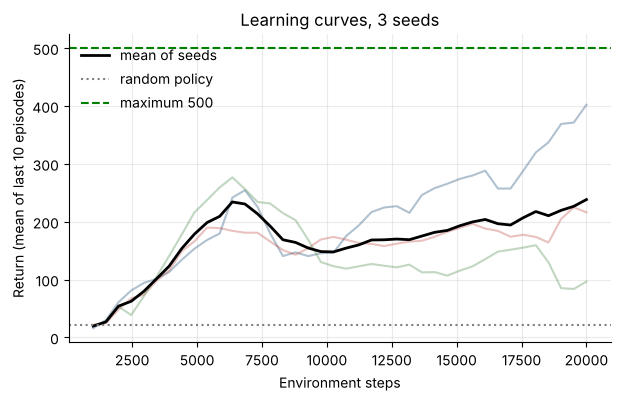

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
curves = np.array([deep.curve_on_grid(runs[s]["steps"], runs[s]["returns"], GRID, window=10) for s in SEEDS])
for c in curves:
    ax.plot(GRID, c, alpha=0.35)
ax.plot(GRID, np.nanmean(curves, axis=0), color="black", linewidth=2, label="mean of seeds")
ax.axhline(random_eval["mean_return"], color="gray", linestyle=":", label="random policy"); ax.axhline(500, color="green", linestyle="--", label="maximum 500")
ax.set_xlabel("Environment steps"); ax.set_ylabel("Return (mean of last 10 episodes)"); ax.set_title("Learning curves, 3 seeds"); ax.legend()
save_figure(fig, NOTEBOOK_ID, "curves"); plt.show()

## 12. Interpretation

Training curves are noisy and a single seed can look great or poor.

In [8]:
print("per seed evaluation return:", np.round(means, 1))
print("a seed counts as solved when its evaluation mean is at least 475; solved seeds:", int((means >= 475).sum()), "of", len(SEEDS))
final_train = np.array([np.mean(runs[s]["returns"][-10:]) for s in SEEDS])
print("training return of last 10 episodes versus evaluation return:", np.round(final_train, 1), "vs", np.round(means, 1))

per seed evaluation return: [500.  488.2  73.7]
a seed counts as solved when its evaluation mean is at least 475; solved seeds: 2 of 3
training return of last 10 episodes versus evaluation return: [402.1 216.2  96.4] vs [500.  488.2  73.7]


## 13. Experiments and Challenges

### Experiment 1: Target network update interval

Update every 1, 250 and 1000 steps. Two seeds and 12 000 steps.

In [9]:
for name, kw in [("every 1 (no real target)", dict(target_every=1)), ("every 250", dict(target_every=250)), ("every 1000", dict(target_every=1000))]:
    rets = []
    for seed in [0, 1]:
        out = deep.train_dqn(seed=seed, total_steps=12000, **kw)
        ev = evaluate_policy(make_env, out["policy"], episodes=10, seed=1000)
        rets.append(ev["mean_return"])
    print(f"{name}: evaluation return by seed {np.round(rets, 1)}, mean {np.mean(rets):.1f}")

every 1 (no real target): evaluation return by seed [9. 9.], mean 9.0


every 250: evaluation return by seed [266.2 164.3], mean 215.2


every 1000: evaluation return by seed [120.2 100. ], mean 110.1


### Experiment 2: Replay buffer size

A tiny buffer keeps only recent, correlated samples. Two seeds and 12 000 steps.

In [10]:
for name, kw in [("buffer 500", dict(buffer_size=500)), ("buffer 20000", dict(buffer_size=20000))]:
    rets = []
    for seed in [0, 1]:
        out = deep.train_dqn(seed=seed, total_steps=12000, **kw)
        ev = evaluate_policy(make_env, out["policy"], episodes=10, seed=1000)
        rets.append(ev["mean_return"])
    print(f"{name}: evaluation return by seed {np.round(rets, 1)}, mean {np.mean(rets):.1f}")

buffer 500: evaluation return by seed [261.4 129.7], mean 195.5


buffer 20000: evaluation return by seed [266.2 164.3], mean 215.2


### Experiment 3: Learning rate

A 100 fold change. Two seeds and 12 000 steps.

In [11]:
for name, kw in [("1e-4", dict(lr=1e-4)), ("1e-3", dict(lr=1e-3)), ("1e-2", dict(lr=1e-2))]:
    rets = []
    for seed in [0, 1]:
        out = deep.train_dqn(seed=seed, total_steps=12000, **kw)
        ev = evaluate_policy(make_env, out["policy"], episodes=10, seed=1000)
        rets.append(ev["mean_return"])
    print(f"{name}: evaluation return by seed {np.round(rets, 1)}, mean {np.mean(rets):.1f}")

1e-4: evaluation return by seed [164.2 107.3], mean 135.8


1e-3: evaluation return by seed [266.2 164.3], mean 215.2


1e-2: evaluation return by seed [24.2 30.6], mean 27.4


### Exercises for learners

1. Repeat with a different set of seeds and report the spread.
2. Change the discount factor and describe what happens to the learned behaviour.
3. Change one hyperparameter by a factor of 10 and compare learning curves.

## 14. Research Discussion

Mnih et al. credit replay and a target network for stability. Our interval experiment tests the target network part on a different task. With two seeds per setting the comparison is only indicative, as Henderson et al. warn.

**Dataset and method differences.** The papers above use other data and protocols. We do not claim that our numbers agree or disagree with them. This notebook only shows whether the behaviour they describe appears on our data.

**Possible improvements.** More seeds, longer training, prioritised replay, and a hyperparameter search with equal budgets.

**Research limitations.** One dataset and one seed for the headline numbers. Three seeds and a CPU sized step budget, so these runs show trends, not converged scores.

## 15. Summary and Further Reading

**Key takeaways**

- DQN = Q-network + replay + target network.
- Curves are noisy, use several seeds.
- Small budgets give weak results.

**Use cases.** Discrete action control from states or images.

**Limitations.** Sample hungry, unstable.

**Recommended next notebook.** Double DQN.

**Further reading.** See `references.md` in this folder.